# 04 — Evaluation on the 2026 test set

**Goal**: compare the JEM with the baselines on data never used for any decision: human bugs and bot bugs filed in **2026**.

**Key findings**

| | Logistic regression | MLP | JEM |
|---|---|---|---|
| Accuracy / macro F1 | 0.459 / 0.400 | 0.469 / 0.401 | 0.470 / 0.399 |
| ECE | 0.096 | 0.045 | 0.046 |
| Bot detection by energy (AUROC) | — | 0.31 | **0.70** |

- **Same classification and ranking** as the MLP, including over three additional seeds.
- **Atypical-bug detection**: 0.61 ± 0.02 (3 seeds) vs 0.31 ± 0.04. Effective on bots with stereotyped texts, ineffective on bots that write like humans.
- A high energy flags an **unusual** bug, not a less reliable prediction.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # paths are relative to the project root (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

In [2]:
from jem_prioriser.cleaning import CLASSES
from jem_prioriser.metrics import ood_auroc, urgency
from jem_prioriser.train import EXPERIMENT, TRACKING_URI, TrainConfig, bots_of_period, predict, prepare_data, train

mlflow.set_tracking_uri(TRACKING_URI)
data = prepare_data()
y_test = data.test["y"].to_numpy()
x_bots_test = bots_of_period(data, "test")

def last_run(name):
    return mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"tags.mlflow.runName = '{name}'",
                              order_by=["start_time DESC"]).iloc[0]

def load_prioriser(name):
    return mlflow.pyfunc.load_model(f"runs:/{last_run(name).run_id}/prioriser").unwrap_python_model().prioriser

mlp, jem = load_prioriser("baseline-mlp"), load_prioriser("jem")
jem_alpha = float(last_run("jem")["params.alpha"])

## 1. Comparison (metrics read from MLflow)

In [3]:
names = {"logreg-C1.0": "Logistic regression", "baseline-mlp": "MLP", "jem": "JEM"}
cols = ["test_accuracy", "test_macro_f1", "test_nll", "test_ece", "test_spearman_urgency",
        "test_p1_recall_top10", "ood_auroc_maxprob", "ood_auroc_energy"]
# logistic regression has no energy: its "ood" columns are empty
table = pd.DataFrame({label: [last_run(run).get(f"metrics.{c}", np.nan) for c in cols] for run, label in names.items()},
                     index=cols).astype(float)
table.round(3)

,Logistic regression,MLP,JEM
test_accuracy,0.459,0.469,0.470
test_macro_f1,0.400,0.401,0.399
test_nll,1.289,1.229,1.234
test_ece,0.096,0.045,0.046
test_spearman_urgency,0.292,0.302,0.307
test_p1_recall_top10,0.237,0.233,0.224
ood_auroc_maxprob,NaN,0.350,0.345
ood_auroc_energy,NaN,0.312,0.703


## 2. Robustness: three additional seeds

In [4]:
rows = []
for seed in [1, 2, 3]:
    for model_name, alpha in [("MLP", 0.0), ("JEM", jem_alpha)]:
        res = train(TrainConfig(alpha=alpha, seed=seed), data, run_name=f"seed{seed}-{'jem' if alpha else 'mlp'}",
                    log_model=False, verbose=False)
        rows.append({"model": model_name, "seed": seed, **res.metrics})
seeds = pd.DataFrame(rows)
seeds.groupby("model")[cols].agg(["mean", "std"]).T.unstack().round(3)

model                    JEM           MLP       
                        mean    std   mean    std
test_accuracy          0.470  0.002  0.470  0.007
test_macro_f1          0.401  0.003  0.404  0.006
test_nll               1.233  0.002  1.239  0.014
test_ece               0.051  0.006  0.057  0.008
test_spearman_urgency  0.307  0.002  0.305  0.001
test_p1_recall_top10   0.209  0.002  0.221  0.013
ood_auroc_maxprob      0.366  0.008  0.363  0.019
ood_auroc_energy       0.607  0.020  0.311  0.041

- Classification and ranking: differences are smaller than the seed-to-seed variability.
- Calibration: ECE 0.051 ± 0.006 (JEM) vs 0.057 ± 0.008 (MLP), a slight, non-decisive advantage.
- Detection: **0.61 ± 0.02 vs 0.31 ± 0.04**, a clear and stable gap. The main run (0.70) sits at the top of the range.
- P1 recall in the top 10% is slightly lower for the JEM (0.21 vs 0.22).

## 3. Calibration and ranking

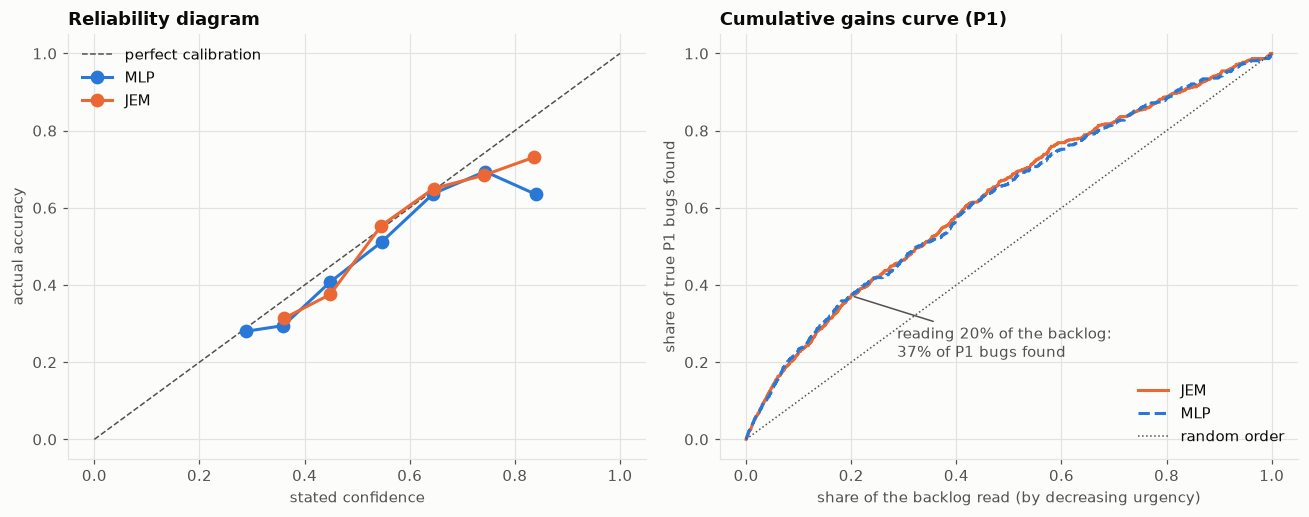

In [5]:
p_mlp, e_mlp = predict(mlp.model, data.x_test)
p_jem, e_jem = predict(jem.model, data.x_test)

def reliability(ax, probs, y, label, color, n_bins=10, **kw):
    conf, correct = probs.max(1), (probs.argmax(1) == y)
    idx = np.clip(np.digitize(conf, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    keep = [b for b in range(n_bins) if (idx == b).sum() >= 20]
    ax.plot([conf[idx == b].mean() for b in keep], [correct[idx == b].mean() for b in keep],
            marker="o", label=label, color=color, **kw)

def gains(score, target):
    order = np.argsort(-score)
    return np.r_[0, np.cumsum(target[order]) / target.sum()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#52514e", linewidth=1, label="perfect calibration")
reliability(axes[0], p_mlp, y_test, "MLP", MODEL_COLORS["MLP"])
reliability(axes[0], p_jem, y_test, "JEM", MODEL_COLORS["JEM"])
axes[0].set_xlabel("stated confidence"); axes[0].set_ylabel("actual accuracy")
axes[0].set_title("Reliability diagram"); axes[0].legend()

frac = np.linspace(0, 1, len(y_test) + 1)
g_jem = gains(urgency(p_jem), y_test == 0)
axes[1].plot(frac, g_jem, label="JEM", color=MODEL_COLORS["JEM"])
axes[1].plot(frac, gains(urgency(p_mlp), y_test == 0), label="MLP", color=MODEL_COLORS["MLP"], linestyle="--")
axes[1].plot([0, 1], [0, 1], color="#52514e", linestyle=":", linewidth=1, label="random order")
g20 = g_jem[int(0.2 * len(y_test))]
axes[1].annotate(f"reading 20% of the backlog:\n{100 * g20:.0f}% of P1 bugs found", (0.2, g20), xytext=(30, -40),
                 textcoords="offset points", color="#52514e", arrowprops={"arrowstyle": "-", "color": "#52514e"})
axes[1].set_xlabel("share of the backlog read (by decreasing urgency)"); axes[1].set_ylabel("share of true P1 bugs found")
axes[1].set_title("Cumulative gains curve (P1)"); axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

- The reliability curves overlap up to ~75% confidence; in the highest bin the JEM is less over-confident (~83% stated for 73% accuracy, vs 84% for 63%), on a few dozen bugs.
- Reading the 20% of bugs ranked most urgent recovers **37% of true P1 bugs** (20% at random). JEM and MLP are indistinguishable.

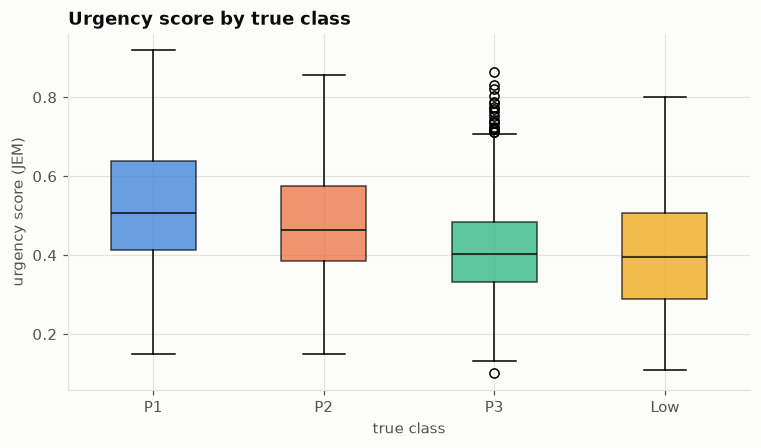

In [6]:
u = urgency(p_jem)
fig, ax = plt.subplots()
bp = ax.boxplot([u[y_test == k] for k in range(len(CLASSES))], tick_labels=CLASSES, patch_artist=True, widths=0.5,
                medianprops={"color": "#0b0b0b"})
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(CLASS_COLORS[c]); patch.set_alpha(0.7)
ax.set_xlabel("true class"); ax.set_ylabel("urgency score (JEM)")
ax.set_title("Urgency score by true class")
plt.show()

Medians are correctly ordered (P1 > P2 > P3 ≈ Low) but overlap heavily: the score is meant to **rank a queue**, not to settle an individual case.

## 4. Atypical-bug detection

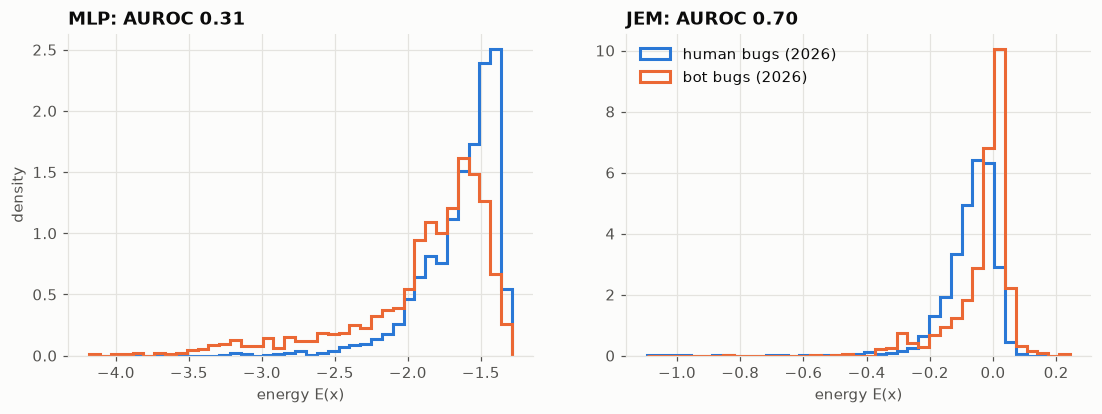

In [7]:
_, eb_mlp = predict(mlp.model, x_bots_test)
_, eb_jem = predict(jem.model, x_bots_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (title, eh, eb) in zip(axes, [("MLP", e_mlp, eb_mlp), ("JEM", e_jem, eb_jem)]):
    bins = np.linspace(min(eh.min(), eb.min()), max(eh.max(), eb.max()), 40)
    ax.hist(eh, bins=bins, density=True, histtype="step", linewidth=2, label="human bugs (2026)", color=HUMAN_BOT_COLORS["humans"])
    ax.hist(eb, bins=bins, density=True, histtype="step", linewidth=2, label="bot bugs (2026)", color=HUMAN_BOT_COLORS["bots"])
    ax.set_title(f"{title}: AUROC {ood_auroc(eh, eb):.2f}"); ax.set_xlabel("energy E(x)")
axes[0].set_ylabel("density"); axes[1].legend()
plt.show()

In [8]:
bots_2026 = data.bots[data.bots.creation_time >= pd.Timestamp("2026-01-01", tz="UTC")].reset_index(drop=True)
bots_2026["account"] = bots_2026.creator.str.split("@").str[0]
by_bot = []
for account, grp in bots_2026.groupby("account"):
    if len(grp) >= 20:
        idx = grp.index.to_numpy()
        by_bot.append({"account": account, "bugs": len(grp),
                       "AUROC JEM": ood_auroc(e_jem, eb_jem[idx]), "AUROC MLP": ood_auroc(e_mlp, eb_mlp[idx])})
pd.DataFrame(by_bot).sort_values("bugs", ascending=False).round(3)

,account,bugs,AUROC JEM,AUROC MLP
3,wptsync,722,0.746,0.328
1,intermittent-bug-filer,397,0.692,0.201
0,bugmon,72,0.480,0.621
2,update-bot,20,0.193,0.513


- Bots with stereotyped texts are well detected: `wptsync` (0.75), `intermittent-bug-filer` (0.69).
- `bugmon` (0.48) replays *fuzzing* test cases and files genuine crash reports; `update-bot` (0.19) opens dependency-update tasks whose vocabulary matches human-written ones.

The energy measures resemblance to human training bugs, not who filed the bug.

In [9]:
threshold = jem.review_threshold
flag = e_jem > threshold
print(f"threshold (95th percentile of training): flagged 2026 human bugs {flag.mean():.1%}"
      f" | flagged 2026 bot bugs {(eb_jem > threshold).mean():.1%}")
print(f"accuracy on flagged human bugs: {(p_jem.argmax(1)[flag] == y_test[flag]).mean():.3f}"
      f" | on the others: {(p_jem.argmax(1)[~flag] == y_test[~flag]).mean():.3f}")
data.test.assign(energy=e_jem).sort_values("energy", ascending=False)[["summary", "component", "label", "energy"]].head(8)

threshold (95th percentile of training): flagged 2026 human bugs 3.0% | flagged 2026 bot bugs 19.7%
accuracy on flagged human bugs: 0.642 | on the others: 0.464


,summary,component,label,energy
349,Incorrect caching of quad gradients in css/css-tables/tentative/paint/background-image...,Graphics: WebRender,P3,0.105738
2198,Consider simplifying Debugger handling of scopes and environments,JavaScript: Debugger API,P2,0.084407
241,View transitions don't deal with reframes of the captured element,CSS Parsing and Computation,P3,0.075918
944,Investigate removing loading add-ons from resource://search-extensions/,Search,P3,0.072771
622,"Rename the functions {Has,Get,CallWIth}IndirectShadowTree",Panning and Zooming,P3,0.067683
795,Telemetry Alert for networking_http_channel_page_open_to_first_sent on 2025-11-15,Networking,Low,0.066699
769,Telemetry Alert for networking_http_channel_page_open_to_first_sent on 2025-11-15,Networking,Low,0.066699
364,i2p TLDs are searched for if http:// isn't typed in,Networking,P2,0.065134


At the tool's threshold, 3% of 2026 human bugs and 20% of 2026 bot bugs are flagged. Flagged human bugs are classified **better** than the rest (64% vs 46%): they are often semi-automated or highly formatted reports ("Telemetry Alert for …", renames, WPT tests), unusual but easy. The `needs_review` flag therefore marks an **atypical bug**, not a doubtful prediction.

## Conclusion

| Question | Result |
|---|---|
| Classify and rank | JEM = MLP ≈ logistic regression (accuracy 0.47, Spearman 0.31, 37% of P1 bugs in the first 20%). Ceiling driven by the labels and the 2026 drift. |
| Calibration | Good for both networks (ECE ≈ 0.05); the JEM is slightly less over-confident at the top of the scale. |
| Atypical bugs | Clear gain: AUROC 0.6-0.7 vs 0.3, at no extra inference cost. |
| Cost | ~13× longer training, one more hyperparameter, detection that varies from one epoch to the next. |

The JEM does not move the classification ceiling; it adds, within the same network, an atypicality signal that a standard classifier lacks.